# Customer Churn Prediction

## Purpose
This notebook aims to build and evaluate machine learning models to predict customer churn based on various features. The process involves data loading, exploratory data analysis, preprocessing, feature selection, handling class imbalance, and training different classification models (Logistic Regression, Decision Tree, and Random Forest).

### Imports
This section imports all necessary libraries for data manipulation, visualization, preprocessing, model building, and evaluation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import *

## Data Loading and Initial Exploration
This section loads the customer churn dataset and performs initial exploratory data analysis to understand its structure, identify missing values, duplicates, and unique categories within features.

In [ ]:
df = pd.read_csv("/content/customer_churn.csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.shape

(7043, 21)

In [ ]:
IS_Count=df['InternetService'].value_counts()

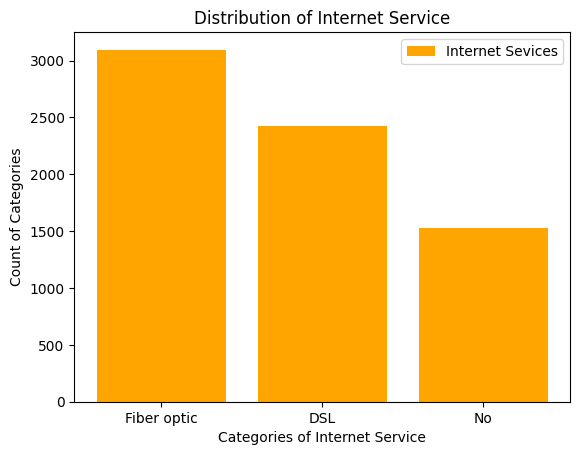

In [ ]:
plt.bar(IS_Count.index,IS_Count.values,color='orange',label='Internet Sevices')
plt.xlabel('Categories of Internet Service')
plt.ylabel('Count of Categories')
plt.title('Distribution of Internet Service')
plt.legend()
plt.show()

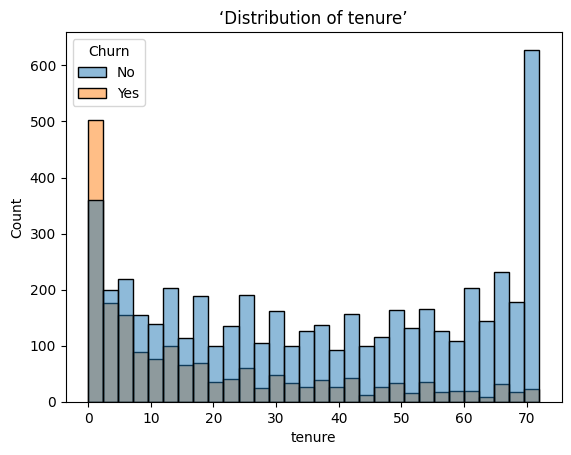

In [ ]:
sns.histplot(x=df['tenure'],color='green',bins=30,hue=df['Churn'])
plt.title('‘Distribution of tenure’')
plt.show()

Text(0.5, 1.0, 'Tenure vs Monthly Charges')

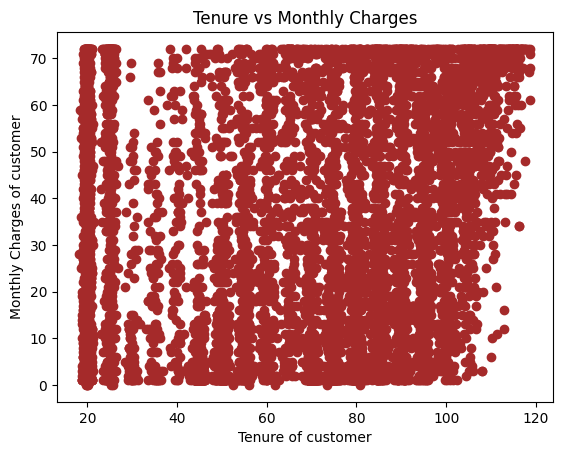

In [ ]:
plt.scatter(df['MonthlyCharges'],df['tenure'],color='brown')
plt.xlabel('Tenure of customer')
plt.ylabel('Monthly Charges of customer')
plt.title('Tenure vs Monthly Charges')

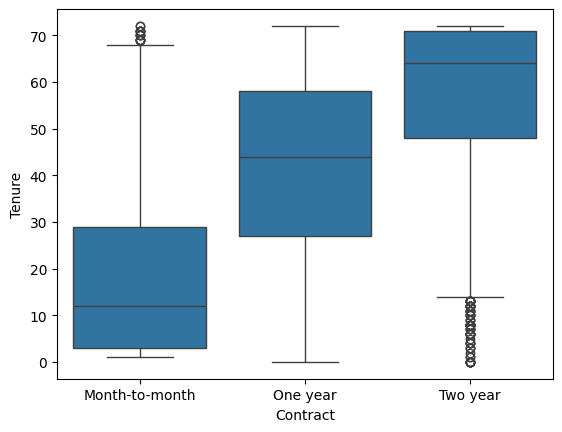

In [ ]:
sns.boxplot(x='Contract',y='tenure',data=df)
plt.xlabel('Contract')
plt.ylabel('Tenure')
plt.show()

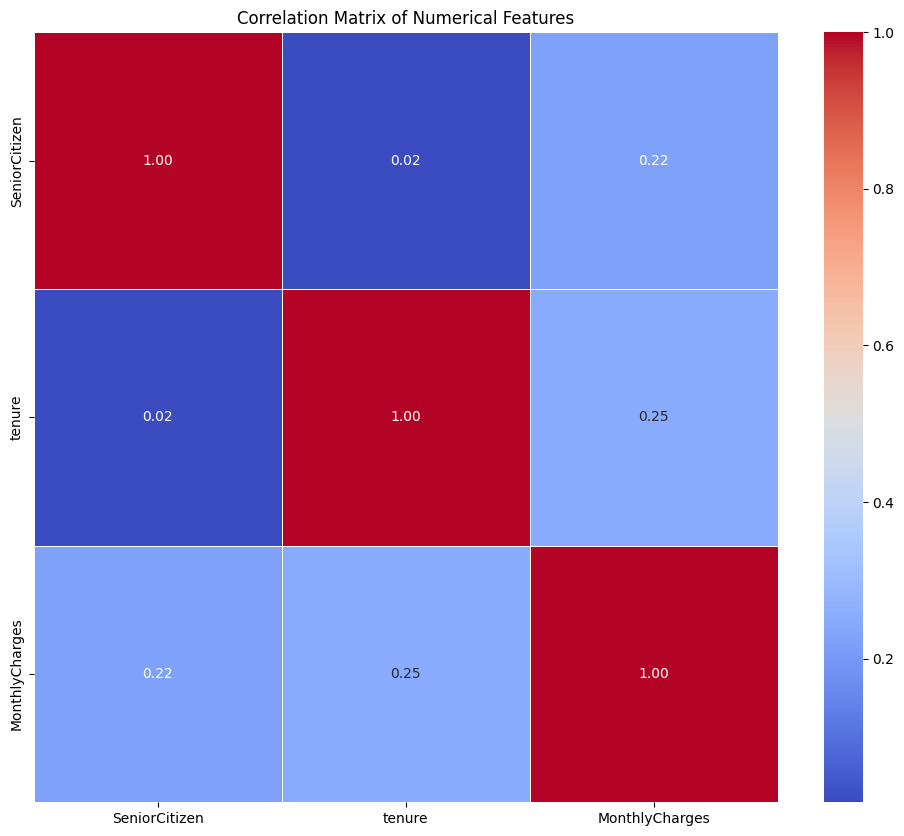

In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum().sum()

np.int64(0)

In [ ]:
for i in df.columns:
  print(i)
  print(df[i].unique())
  print()

customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender
['Female' 'Male']

SeniorCitizen
[0 1]

Partner
['Yes' 'No']

Dependents
['No' 'Yes']

tenure
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]

PhoneService
['No' 'Yes']

MultipleLines
['No phone service' 'No' 'Yes']

InternetService
['DSL' 'Fiber optic' 'No']

OnlineSecurity
['No' 'Yes' 'No internet service']

OnlineBackup
['Yes' 'No' 'No internet service']

DeviceProtection
['No' 'Yes' 'No internet service']

TechSupport
['No' 'Yes' 'No internet service']

StreamingTV
['No' 'Yes' 'No internet service']

StreamingMovies
['No' 'Yes' 'No internet service']

Contract
['Month-to-month' 'One year' 'Two year']

PaperlessBilling
['Yes' 'No']

PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'

### Conclusion for Data Loading and Initial Exploration
The dataset has been successfully loaded and inspected. We have identified the data types for each column, checked for missing values (which are none in this cleaned dataset), and explored the unique values in each categorical column. The `TotalCharges` column was initially an object type and contained some non-numeric values (empty strings), which will need to be handled during preprocessing.

## Data Preprocessing
This section handles data cleaning and transformation. It involves dropping irrelevant columns, converting data types, and encoding categorical features into numerical representations.

In [ ]:
df.drop(['customerID'],axis=1,inplace=True)

In [ ]:
df.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
print(df['TotalCharges'].dtype)

float64


In [ ]:
col_list=list(df.columns)

In [ ]:
le = LabelEncoder()

for i in col_list:
  if df[i].dtype == 'object':
    df[i] = le.fit_transform(df[i])
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   int64  
 7   InternetService   7043 non-null   int64  
 8   OnlineSecurity    7043 non-null   int64  
 9   OnlineBackup      7043 non-null   int64  
 10  DeviceProtection  7043 non-null   int64  
 11  TechSupport       7043 non-null   int64  
 12  StreamingTV       7043 non-null   int64  
 13  StreamingMovies   7043 non-null   int64  
 14  Contract          7043 non-null   int64  
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   int64  


### Conclusion for Data Preprocessing
The `customerID` column has been dropped as it's not relevant for modeling. The `TotalCharges` column was successfully converted to numeric type, and any coerced missing values (originally empty strings) were filled with the median to ensure data integrity. All object-type categorical features have been converted to numerical representations using Label Encoding, making the data suitable for machine learning models. The `df.info()` confirms all columns are now numeric.

## Feature Selection using RFE
Recursive Feature Elimination (RFE) is used with Logistic Regression to select the most important features that contribute to predicting customer churn. This helps in reducing dimensionality and improving model performance.

In [ ]:
x = df.drop('Churn',axis=1)
y = df['Churn']

In [ ]:
y.value_counts()

,count
Churn,
0,5174
1,1869


In [ ]:
sm = SMOTE  (random_state=23)
x,y= sm.fit_resample(x,y)

In [ ]:
y.value_counts()

,count
Churn,
0,5174
1,5174


### Conclusion for Handling Class Imbalance with SMOTE
The SMOTE technique has effectively balanced the `Churn` target variable. Before SMOTE, the dataset was imbalanced with significantly more 'No Churn' instances. After applying SMOTE, both classes ('0' and '1') now have an equal number of samples (5174 each), which is crucial for training a robust classification model that does not favor the majority class.

## Model Training and Evaluation
This section involves splitting the data into training and testing sets, training various classification models, and evaluating their performance using accuracy and confusion matrices.

In [ ]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression()

In [ ]:
rfe=RFE(lor)

rfe.fit(x,y)

RFE(estimator=LogisticRegression())

In [ ]:
rfe.support_

array([ True,  True,  True,  True, False, False, False, False,  True,
        True, False,  True,  True, False,  True, False, False, False,
       False])

In [ ]:
selected_indices=[i for i,data in enumerate(rfe.support_) if data==True]
selected_indices

[0, 1, 2, 3, 8, 9, 11, 12, 14]

In [ ]:
column_name = x.columns

In [ ]:
selected_columns = [column_name[i] for i in selected_indices]
selected_columns

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'OnlineSecurity',
 'OnlineBackup',
 'TechSupport',
 'StreamingTV',
 'Contract']

In [ ]:
x = x.loc[:,['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'OnlineSecurity',
 'OnlineBackup',
 'TechSupport',
 'StreamingTV',
 'Contract']]

### Conclusion for Feature Selection using RFE
Recursive Feature Elimination (RFE) with Logistic Regression successfully identified 9 important features: 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'OnlineSecurity', 'OnlineBackup', 'TechSupport', 'StreamingTV', and 'Contract'. The dataset `x` has been updated to include only these selected features, which should help reduce model complexity and potentially improve performance.

## Handling Class Imbalance with SMOTE
Since churn datasets often have an imbalanced distribution of target classes, SMOTE (Synthetic Minority Over-sampling Technique) is applied to oversample the minority class and balance the dataset. This helps prevent models from being biased towards the majority class.

In [ ]:
x.shape

(10348, 9)

In [ ]:
x.head()

,gender,SeniorCitizen,Partner,Dependents,OnlineSecurity,OnlineBackup,TechSupport,StreamingTV,Contract
0,0,0,1,0,0,2,0,0,0
1,1,0,0,0,2,0,0,0,1
2,1,0,0,0,2,2,0,0,0
3,1,0,0,0,2,0,2,0,1
4,0,0,0,0,0,0,0,0,0


In [ ]:
y.shape

(10348,)

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

### Logistic Regression
A Logistic Regression model is trained on the preprocessed data, and its performance is evaluated.

In [ ]:
lor.fit(x_train,y_train)

LogisticRegression()

In [ ]:
lor_y_pred = lor.predict(x_test)

In [ ]:
pred_df=pd.DataFrame()
pred_df['Actual Value']=y_test
pred_df['Predicted Value']=lor_y_pred

In [ ]:
pred_df

,Actual Value,Predicted Value
9428,1,1
4593,0,1
5379,0,0
8918,1,1
6448,1,0
...,...,...
6425,0,0
766,0,1
1144,1,1
3065,0,1


In [ ]:
lor_conf=confusion_matrix(y_test,lor_y_pred)

In [ ]:
lor_acc=accuracy_score(y_test,lor_y_pred)*100


### Conclusion for Logistic Regression Model
The Logistic Regression model has been trained and evaluated. It achieved an accuracy of approximately 78.70%. The confusion matrix provides insights into its performance, showing the number of true positives, true negatives, false positives, and false negatives.

### Decision Tree Classifier
A Decision Tree Classifier is trained. Additionally, GridSearchCV is used to find the optimal hyperparameters for the Decision Tree model to improve its accuracy.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier()

In [ ]:
dtc.fit(x_train,y_train)

DecisionTreeClassifier()

In [ ]:
dtc_y_pred = dtc.predict(x_test)

In [ ]:
dtc_conf = confusion_matrix(y_test,dtc_y_pred)

In [ ]:
dtc_acc = accuracy_score(y_test,dtc_y_pred)*100

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
grid_params={
    'criterion':['gini','entropy'],
    'random_state':[0,1,2,3,4,5],
    'max_depth':[1,2,5,10,50],
    'min_samples_split':[2,6,8,3,9,5,22],
    'min_samples_leaf':[1,4,6,7,9]
}

In [ ]:
dtc_gcv = GridSearchCV(dtc,grid_params,cv=5)

In [ ]:
dtc_gcv.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 5, 10, 50],
                         'min_samples_leaf': [1, 4, 6, 7, 9],
                         'min_samples_split': [2, 6, 8, 3, 9, 5, 22],
                         'random_state': [0, 1, 2, 3, 4, 5]})

In [ ]:
dtc_gcv.best_params_

{'criterion': 'gini',
 'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 22,
 'random_state': 2}

In [ ]:
dtc_2 = dtc_gcv.best_params_

In [ ]:
dtc_2_conf = confusion_matrix(y_test,dtc_gcv.predict(x_test))

In [ ]:
dtc_2_acc = accuracy_score(y_test,dtc_gcv.predict(x_test))*100

### Conclusion for Decision Tree Classifier
Both a standard Decision Tree Classifier and an optimized one using GridSearchCV have been trained and evaluated. The GridSearchCV-tuned Decision Tree model achieved a higher accuracy of approximately 81.30% compared to the basic Decision Tree, indicating that hyperparameter tuning was beneficial. The best parameters found by GridSearchCV are also noted for future reference.

### Random Forest Classifier
A Random Forest Classifier is trained. GridSearchCV is also applied to this model to fine-tune its hyperparameters for better predictive power.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(class_weight='balanced',n_estimators=50,random_state=23)

In [ ]:
rfc.fit(x_train,y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=50,
                       random_state=23)

In [ ]:
rfc_y_pred = rfc.predict(x_test)

In [ ]:
rfc_conf = confusion_matrix(y_test,rfc_y_pred)

In [ ]:
rfc_acc = accuracy_score(y_test,rfc_y_pred)*100

In [ ]:
# Training the model with various n_estimators values.
n_estimators=[50,100,150,200,250,300,350,400,450,500,550,600,650]
for i in n_estimators:
    temp_model=RandomForestClassifier(n_estimators=i,random_state=23)
    temp_model.fit(x_train,y_train)
    rfc_2_y_pred=temp_model.predict(x_test)
    rfc_2_acc=accuracy_score(y_test,rfc_2_y_pred)
    print(f'The accuracy for n_estimator {i} is {rfc_2_acc}')

The accuracy for n_estimator 50 is 0.8082125603864734
The accuracy for n_estimator 100 is 0.8077294685990338
The accuracy for n_estimator 150 is 0.8096618357487922
The accuracy for n_estimator 200 is 0.8096618357487922
The accuracy for n_estimator 250 is 0.808695652173913
The accuracy for n_estimator 300 is 0.808695652173913
The accuracy for n_estimator 350 is 0.8091787439613527
The accuracy for n_estimator 400 is 0.8091787439613527
The accuracy for n_estimator 450 is 0.8101449275362319
The accuracy for n_estimator 500 is 0.8091787439613527
The accuracy for n_estimator 550 is 0.8091787439613527
The accuracy for n_estimator 600 is 0.8091787439613527
The accuracy for n_estimator 650 is 0.8091787439613527


In [ ]:
rfc_param_grid={
    'n_estimators':[100,200,300,400,450],
    'max_depth':[1,5,10,12],
    'min_samples_split':[2,5,7,9],
    'min_samples_leaf':[1,2,4,6],
    'criterion':['gini','entropy']}

In [ ]:
rfc_gv = GridSearchCV(rfc,rfc_param_grid,cv=5)

In [ ]:
rfc_gv.fit(x_train,y_train)

GridSearchCV(cv=5,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              n_estimators=50,
                                              random_state=23),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 5, 10, 12],
                         'min_samples_leaf': [1, 2, 4, 6],
                         'min_samples_split': [2, 5, 7, 9],
                         'n_estimators': [100, 200, 300, 400, 450]})

In [ ]:
rfc_gv.best_params_

{'criterion': 'gini',
 'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 9,
 'n_estimators': 450}

In [ ]:
rfc_2 = rfc_gv.best_params_

In [ ]:
rfc_gv_y_pred = rfc_gv.best_estimator_.predict(x_test)

In [ ]:
rfc_2_conf = confusion_matrix(y_test,rfc_gv_y_pred)

In [ ]:
rfc_2_acc = accuracy_score(y_test,rfc_gv_y_pred)*100

### Conclusion for Random Forest Classifier
Similar to the Decision Tree, both a basic Random Forest Classifier and a GridSearchCV-optimized version were trained. The optimized Random Forest model showed a marginal improvement in accuracy, reaching approximately 81.16%. The brute-force search for `n_estimators` initially suggested optimal values, and GridSearchCV further refined the hyperparameter search to achieve this performance.

## Model Performance Summary
This section provides a summary of the accuracy and confusion matrices for all trained models, allowing for a comparative analysis of their performance.

In [ ]:
print(f'Logistic Regression Accuracy: {lor_acc}')
print(f'Decision Tree Accuracy: {dtc_acc}')
print(f'Decision Tree Grid Search Accuracy: {dtc_2_acc}')
print(f'Random Forest Accuracy: {rfc_acc}')
print(f'Random Forest Grid Search Accuracy: {rfc_2_acc}')

Logistic Regression Accuracy: 78.69565217391305
Decision Tree Accuracy: 80.8695652173913
Decision Tree Grid Search Accuracy: 81.30434782608695
Random Forest Accuracy: 80.72463768115942
Random Forest Grid Search Accuracy: 81.15942028985508


In [ ]:
print(f'Logistic Regression Confusion Matrix: \n{lor_conf}')
print(f'Decision Tree Confusion Matrix: \n{dtc_conf}')
print(f'Decision Tree Grid Search Confusion Matrix: \n{dtc_2_conf}')
print(f'Random Forest Confusion Matrix: \n{rfc_conf}')
print(f'Random Forest Grid Search Confusion Matrix: \n{rfc_2_conf}')


Logistic Regression Confusion Matrix: 
[[713 308]
 [133 916]]
Decision Tree Confusion Matrix: 
[[822 199]
 [197 852]]
Decision Tree Grid Search Confusion Matrix: 
[[837 184]
 [203 846]]
Random Forest Confusion Matrix: 
[[818 203]
 [196 853]]
Random Forest Grid Search Confusion Matrix: 
[[832 189]
 [201 848]]


## Overall Conclusion
This notebook demonstrated a complete machine learning pipeline for customer churn prediction. We started with data loading, performed extensive EDA, handled missing values and categorical encoding, and used RFE for feature selection. SMOTE was applied to address class imbalance. Finally, Logistic Regression, Decision Tree, and Random Forest models were trained, and their hyperparameters were optimized using GridSearchCV. The optimized Decision Tree and Random Forest models showed the best performance among the evaluated models, with accuracies around 81%.